# MNIST + SVD classroom demo

1. Load the MNIST handwritten-digit dataset.
2. Show that a single digit is stored as a **28 × 28 matrix** of pixel intensities.
3. Compute the SVD of that matrix: $A = U \, \Sigma \, V^T$
4. Keep only the $k$ largest singular values ($k = 10, 15, 20, 25$) and rebuild the image.
5. Compare the original and each low-rank reconstruction side by side.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

np.set_printoptions(linewidth=200)  # so a 28-wide row prints on one line

## 1. Load MNIST
Tries a few common libraries and uses whichever is installed.

In [ ]:
def load_mnist():
    try:                                   # option A: tensorflow / keras
        from tensorflow.keras.datasets import mnist
        (x_train, y_train), _ = mnist.load_data()
        return x_train, y_train
    except ImportError:
        pass
    try:                                   # option B: torchvision
        from torchvision import datasets
        ds = datasets.MNIST(root="./data", train=True, download=True)
        return ds.data.numpy(), ds.targets.numpy()
    except ImportError:
        pass
    # option C: scikit-learn (downloads from OpenML, ~15 MB)
    from sklearn.datasets import fetch_openml
    d = fetch_openml("mnist_784", version=1, as_frame=False)
    return d.data.reshape(-1, 28, 28).astype(np.uint8), d.target.astype(int)


images, labels = load_mnist()
print(f"Dataset shape : {images.shape}   -> {images.shape[0]} images, each {images.shape[1]} x {images.shape[2]}")
print(f"Pixel range   : {images.min()} .. {images.max()}  (0 = black, 255 = white)")

100.0%
100.0%
100.0%
100.0%

Dataset shape : (60000, 28, 28)   -> 60000 images, each 28 x 28
Pixel range   : 0 .. 255  (0 = black, 255 = white)


## 2. One digit is just a 28 × 28 matrix
Each entry is a pixel intensity between 0 (black) and 255 (white).

In [ ]:
idx = 287                      # change this to look at a different digit
A = images[idx].astype(float)
print(f"Image #{idx} is the digit '{labels[idx]}'.  Its matrix A has shape {A.shape}.\n")
print("The full 28 x 28 matrix of pixel values:")
print(A.astype(int))

Image #287 is the digit '5'.  Its matrix A has shape (28, 28).

The full 28 x 28 matrix of pixel values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0  10  40 137 196 196 137 136 136 

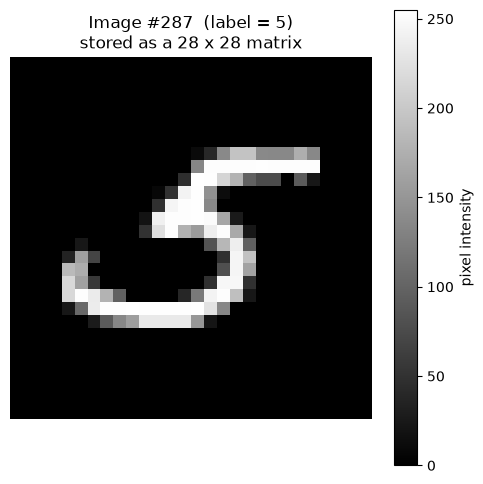

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(A, cmap="gray")
plt.title(f"Image #{idx}  (label = {labels[idx]})\nstored as a 28 x 28 matrix")
plt.colorbar(label="pixel intensity")
plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Singular Value Decomposition
$A = U \, \mathrm{diag}(s) \, V^T$

In [ ]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(f"U  shape: {U.shape}")
print(f"s  shape: {s.shape}   (the 28 singular values, largest first)")
print(f"Vt shape: {Vt.shape}\n")
print("Singular values:")
print(np.round(s, 2))

# Check that the factorisation really reproduces A
print(f"\nmax |A - U S Vt| = {np.abs(A - U @ np.diag(s) @ Vt).max():.2e}  (should be ~0)")

U  shape: (28, 28)
s  shape: (28,)   (the 28 singular values, largest first)
Vt shape: (28, 28)

Singular values:
[1419.5   980.12  656.28  489.69  387.22  302.01  210.38  160.09  107.86   87.71   59.04   49.41   44.03   10.36    0.      0.      0.      0.      0.      0.      0.      0.      0.      0.
    0.      0.      0.      0.  ]

max |A - U S Vt| = 9.66e-13  (should be ~0)


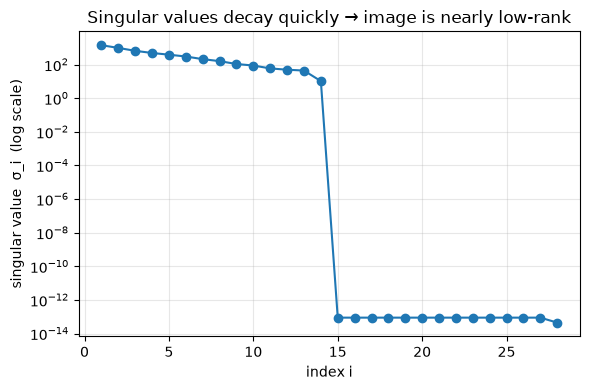

In [ ]:
plt.figure(figsize=(6, 4))
plt.semilogy(np.arange(1, 29), s, "o-")
plt.xlabel("index i")
plt.ylabel("singular value  σ_i  (log scale)")
plt.title("Singular values decay quickly → image is nearly low-rank")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Rank-$k$ reconstruction
Keep the first $k$ singular values and zero out the rest:
$A_k = U_{:,1:k} \, \mathrm{diag}(s_{1:k}) \, V^T_{1:k,:}$

In [ ]:
def reconstruct(U, s, Vt, k):
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]


ks = [1,2,3,5,10, 15,19]

k =  1:  relative error = 70.31%   energy kept = 50.57%   numbers stored = 57
k =  2:  relative error = 50.32%   energy kept = 74.68%   numbers stored = 114
k =  3:  relative error = 38.09%   energy kept = 85.49%   numbers stored = 171
k =  5:  relative error = 21.74%   energy kept = 95.27%   numbers stored = 285
k = 10:  relative error =  4.47%   energy kept = 99.80%   numbers stored = 570
k = 15:  relative error =  0.00%   energy kept = 100.00%   numbers stored = 855
k = 19:  relative error =  0.00%   energy kept = 100.00%   numbers stored = 1083


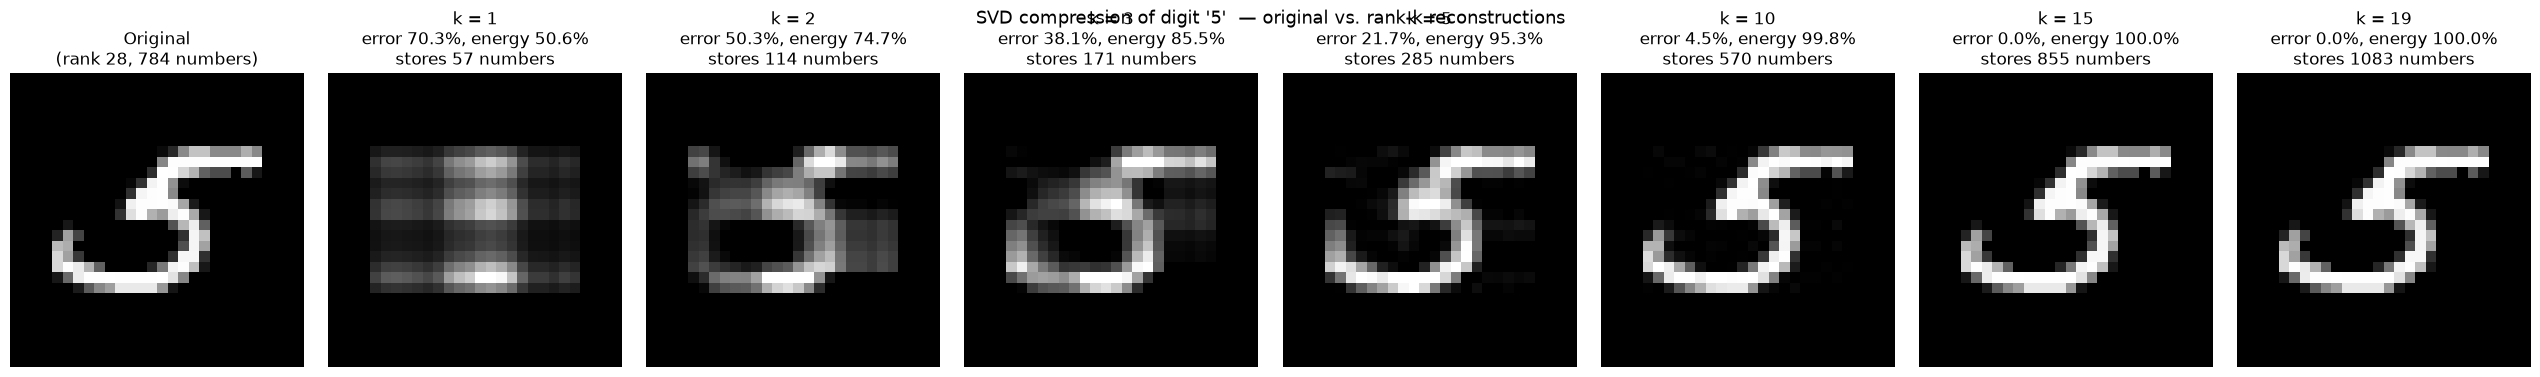

In [ ]:
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(3.2 * (len(ks) + 1), 3.8))
axes[0].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original\n(rank 28, 784 numbers)")
axes[0].axis("off")

total_energy = np.sum(s**2)
for ax, k in zip(axes[1:], ks):
    A_k = reconstruct(U, s, Vt, k)
    err = np.linalg.norm(A - A_k) / np.linalg.norm(A)        # relative Frobenius error
    energy = np.sum(s[:k]**2) / total_energy                 # fraction of "energy" kept
    stored = k * (28 + 28 + 1)                               # numbers needed to store U_k, s_k, Vt_k
    ax.imshow(A_k, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}\nerror {err:.1%}, energy {energy:.1%}\nstores {stored} numbers")
    ax.axis("off")
    print(f"k = {k:2d}:  relative error = {err:6.2%}   energy kept = {energy:6.2%}   numbers stored = {stored}")

fig.suptitle(f"SVD compression of digit '{labels[idx]}'  — original vs. rank-k reconstructions", fontsize=13)
plt.tight_layout()
plt.show()

## 5. Side-by-side pairs, one figure per $k$
Useful for stepping through one value of $k$ at a time in class.

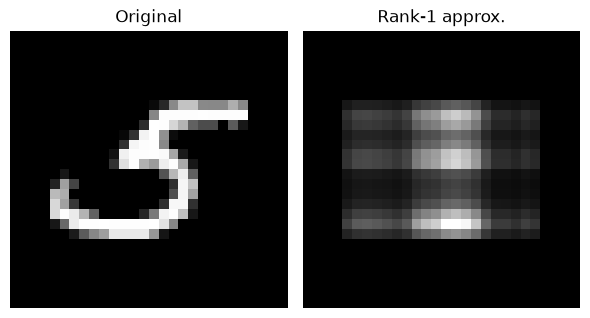

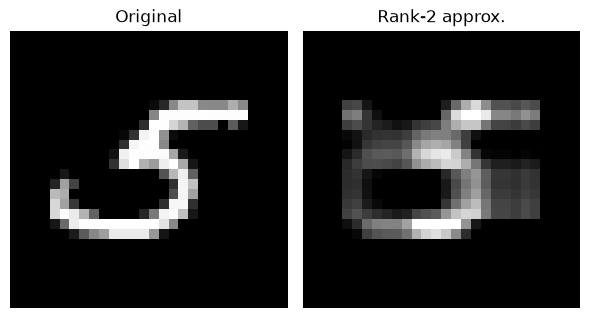

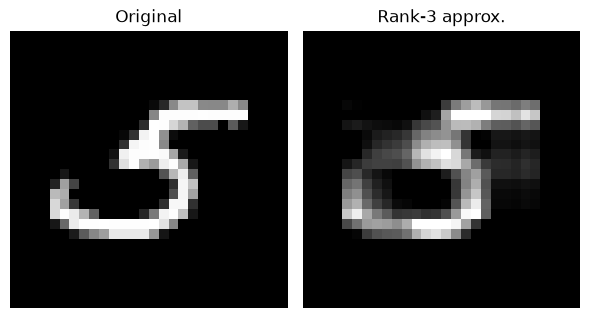

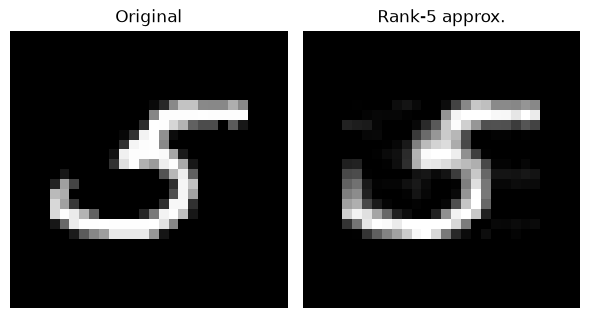

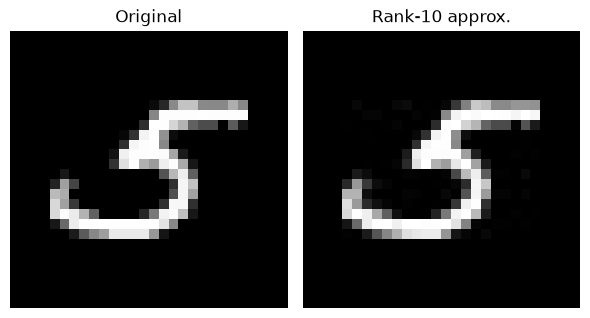

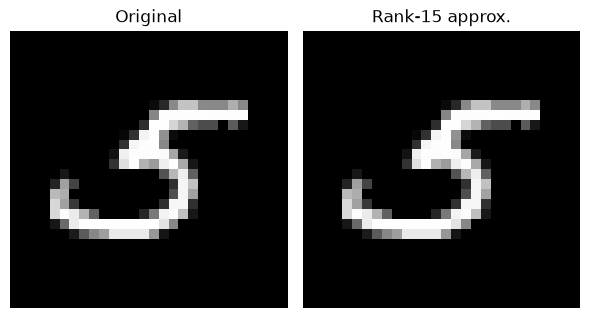

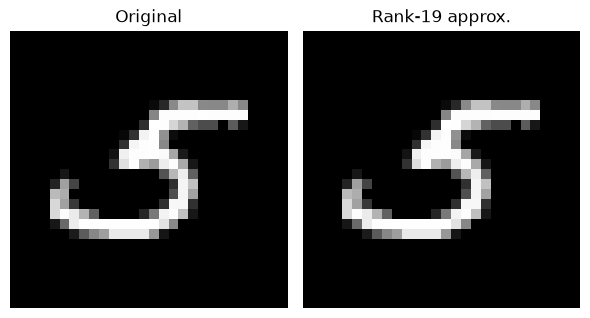

In [ ]:
for k in ks:
    A_k = reconstruct(U, s, Vt, k)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3.3))
    ax1.imshow(A, cmap="gray", vmin=0, vmax=255);   ax1.set_title("Original");          ax1.axis("off")
    ax2.imshow(A_k, cmap="gray", vmin=0, vmax=255); ax2.set_title(f"Rank-{k} approx."); ax2.axis("off")
    plt.tight_layout()
    plt.show()